In [2]:

# Cell 1 — TB Multimodal Metadata Inspection

from google.colab import drive
drive.mount("/content/drive")

import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Major_Project/Tuberculosis"
)

OUTPUT_DIR = BASE / "outputs"

train_df = pd.read_csv(OUTPUT_DIR / "tb_train.csv")
val_df = pd.read_csv(OUTPUT_DIR / "tb_val.csv")
test_df = pd.read_csv(OUTPUT_DIR / "tb_test.csv")

metadata_path = BASE / "data" / "shenzhen_metadata.csv"
metadata_df = pd.read_csv(metadata_path)

print("TB MULTIMODAL FUSION — METADATA INSPECTION")
print("=" * 65)

# 1. Dataset sizes
print("\nDATASET SPLITS")
print("-" * 45)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"{name}: {len(df)} images")

# 2. Available columns
print("\nSPLIT CSV COLUMNS")
print("-" * 45)
print(train_df.columns.tolist())

print("\nSOURCE METADATA COLUMNS")
print("-" * 45)
print(metadata_df.columns.tolist())

# 3. Inspect possible age/sex columns
print("\nAGE AND SEX COLUMN CANDIDATES")
print("-" * 45)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
    ("Source metadata", metadata_df)
]:
    candidates = [
        col for col in df.columns
        if any(
            word in col.lower()
            for word in ["age", "sex", "gender"]
        )
    ]

    print(f"\n{name}: {candidates}")

    for col in candidates:
        print(f"  {col}:")
        print(f"    Missing: {df[col].isna().sum()}")

        if pd.api.types.is_numeric_dtype(df[col]):
            print(
                f"    Range: {df[col].min()} "
                f"to {df[col].max()}"
            )
        else:
            print(
                "    Values:",
                df[col].value_counts(
                    dropna=False
                ).head(10).to_dict()
            )

# 4. Identify potential linkage columns
print("\nPOSSIBLE METADATA LINKAGE COLUMNS")
print("-" * 45)

common_columns = sorted(
    set(train_df.columns)
    & set(metadata_df.columns)
)

print("Columns shared by train and source metadata:")
print(common_columns)

# 5. Check class distribution
print("\nCLASS DISTRIBUTION")
print("-" * 45)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}:",
        df["label"].value_counts(
            sort=False
        ).to_dict()
    )

# 6. Preview metadata safely
print("\nTRAINING DATA PREVIEW")
print("-" * 45)

safe_columns = [
    col for col in train_df.columns
    if col.lower() not in [
        "findings", "finding",
        "clinical_findings"
    ]
]

print(
    train_df[safe_columns].head(5).to_string(
        index=False
    )
)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TB MULTIMODAL FUSION — METADATA INSPECTION

DATASET SPLITS
---------------------------------------------
Train: 463 images
Validation: 99 images
Test: 100 images

SPLIT CSV COLUMNS
---------------------------------------------
['study_id', 'sex', 'age', 'findings', 'label', 'image_path']

SOURCE METADATA COLUMNS
---------------------------------------------
['study_id', 'sex', 'age', 'findings']

AGE AND SEX COLUMN CANDIDATES
---------------------------------------------

Train: ['sex', 'age', 'image_path']
  sex:
    Missing: 0
    Values: {'Male': 332, 'Female': 131}
  age:
    Missing: 0
    Range: 1 to 82
  image_path:
    Missing: 0
    Values: {'/content/drive/MyDrive/Major_Project/Tuberculosis/data/images/CHNCXR_0200_0.png': 1, '/content/drive/MyDrive/Major_Project/Tuberculosis/data/images/CHNCXR_0146_0.png': 1, '/content/drive/MyDrive/Major_Project/Tu

In [4]:

# Cell 2 — Verify TB Metadata Linkage and Prepare Features

import numpy as np
import pandas as pd
from pathlib import Path

# 1. Check study IDs are unique in source metadata
assert metadata_df["study_id"].is_unique, (
    "Duplicate study_id values found in source metadata."
)

# 2. Verify each split against the original metadata
source = metadata_df[
    ["study_id", "age", "sex"]
].copy()

for split_name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    assert df["study_id"].is_unique, (
        f"Duplicate study IDs in {split_name}."
    )

    assert (
        df["study_id"].astype(str)
        == df["image_path"].map(
            lambda p: Path(p).name
        )
    ).all(), (
        f"Image filename mismatch in {split_name}."
    )

    matched = df.merge(
        source,
        on="study_id",
        how="left",
        validate="one_to_one",
        suffixes=("", "_source"),
        indicator=True
    )

    assert (matched["_merge"] == "both").all(), (
        f"Missing metadata linkage in {split_name}."
    )

    age_match = (
        matched["age"] == matched["age_source"]
    ).all()

    sex_match = (
        matched["sex"] == matched["sex_source"]
    ).all()

    assert age_match and sex_match, (
        f"Age/sex mismatch in {split_name}."
    )

    print(
        f"{split_name}: {len(df)} records "
        f"correctly linked to source metadata."
    )

# 3. Validate metadata values
all_splits = [train_df, val_df, test_df]

for df in all_splits:
    assert df["age"].notna().all()
    assert df["sex"].notna().all()
    assert df["age"].between(0, 120).all()
    assert set(df["sex"].unique()).issubset(
        {"Male", "Female"}
    )

# 4. Calculate age normalization from TRAINING DATA ONLY
age_mean = float(train_df["age"].mean())
age_std = float(train_df["age"].std(ddof=0))

assert age_std > 0

print("\nTRAINING-ONLY NORMALIZATION")
print("-" * 50)
print(f"Training age mean: {age_mean:.4f}")
print(f"Training age standard deviation: {age_std:.4f}")

# 5. Encode features
sex_mapping = {
    "Female": 0,
    "Male": 1
}

def prepare_metadata(df):
    prepared = df.copy()

    prepared["age_normalized"] = (
        prepared["age"] - age_mean
    ) / age_std

    prepared["sex_encoded"] = (
        prepared["sex"].map(sex_mapping).astype(float)
    )

    return prepared

train_fusion_df = prepare_metadata(train_df)
val_fusion_df = prepare_metadata(val_df)
test_fusion_df = prepare_metadata(test_df)

# 6. Verify final model inputs
feature_columns = [
    "age_normalized",
    "sex_encoded"
]

for name, df in [
    ("Train", train_fusion_df),
    ("Validation", val_fusion_df),
    ("Test", test_fusion_df)
]:
    features = df[feature_columns].to_numpy(
        dtype=np.float32
    )

    assert np.isfinite(features).all()

    print(
        f"{name} metadata feature shape: "
        f"{features.shape}"
    )

print("\nTRAINING METADATA PREVIEW")
print("-" * 50)

print(
    train_fusion_df[
        [
            "study_id",
            "age",
            "sex",
            "age_normalized",
            "sex_encoded",
            "label"
        ]
    ].head(5).to_string(index=False)
)


Train: 463 records correctly linked to source metadata.
Validation: 99 records correctly linked to source metadata.
Test: 100 records correctly linked to source metadata.

TRAINING-ONLY NORMALIZATION
--------------------------------------------------
Training age mean: 35.2505
Training age standard deviation: 14.2298
Train metadata feature shape: (463, 2)
Validation metadata feature shape: (99, 2)
Test metadata feature shape: (100, 2)

TRAINING METADATA PREVIEW
--------------------------------------------------
         study_id  age    sex  age_normalized  sex_encoded  label
CHNCXR_0200_0.png   24   Male       -0.790635          1.0      0
CHNCXR_0146_0.png   22   Male       -0.931186          1.0      0
CHNCXR_0155_0.png    5   Male       -2.125866          1.0      0
CHNCXR_0266_0.png   23   Male       -0.860910          1.0      0
CHNCXR_0261_0.png   25 Female       -0.720360          0.0      0


In [6]:

# Cell 3 — TB Early-Fusion DenseNet-121 Architecture

import torch
import torch.nn as nn
from torchvision.models import densenet121
from pathlib import Path

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Existing optimized TB image-only checkpoint
IMAGE_CHECKPOINT = (
    OUTPUT_DIR / "optimization" /
    "lr_3e-04" / "best_model.pth"
)

assert IMAGE_CHECKPOINT.exists(), (
    f"Checkpoint not found: {IMAGE_CHECKPOINT}"
)

# 1. Reconstruct optimized image-only DenseNet
image_model = densenet121(weights=None)
image_model.classifier = nn.Linear(
    image_model.classifier.in_features, 2
)

checkpoint = torch.load(
    IMAGE_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

image_model.load_state_dict(state_dict, strict=True)

# 2. Create five-channel early-fusion model
early_model = densenet121(weights=None)
early_model.classifier = nn.Linear(
    early_model.classifier.in_features, 2
)

# Replace first convolution: RGB (3) -> RGB + age + sex (5)
old_conv = early_model.features.conv0

new_conv = nn.Conv2d(
    in_channels=5,
    out_channels=old_conv.out_channels,
    kernel_size=old_conv.kernel_size,
    stride=old_conv.stride,
    padding=old_conv.padding,
    bias=False
)

early_model.features.conv0 = new_conv

# 3. Transfer optimized image-model weights
# All layers except the first convolution have matching shapes
early_state = early_model.state_dict()
image_state = image_model.state_dict()

for name, weights in image_state.items():
    if name != "features.conv0.weight":
        early_state[name] = weights.clone()

# Preserve original RGB filters
early_state["features.conv0.weight"][:, :3] = (
    image_state["features.conv0.weight"].clone()
)

# Initialize new metadata-channel filters to zero
# Initially, the model behaves like the optimized image-only model
early_state["features.conv0.weight"][:, 3:] = 0.0

early_model.load_state_dict(early_state, strict=True)
early_model = early_model.to(device)

# 4. Freeze DenseNet backbone initially
for parameter in early_model.features.parameters():
    parameter.requires_grad = False

# Unfreeze first convolution so metadata channels can learn
for parameter in early_model.features.conv0.parameters():
    parameter.requires_grad = True

# Train the classifier as well
for parameter in early_model.classifier.parameters():
    parameter.requires_grad = True

# 5. Test architecture with a synthetic batch
dummy_images = torch.randn(2, 3, 224, 224)
dummy_metadata = torch.tensor(
    [
        [0.25, 1.0],
        [-0.50, 0.0]
    ],
    dtype=torch.float32
)

# Broadcast age and sex across the image's spatial dimensions
metadata_channels = dummy_metadata[:, :, None, None]
metadata_channels = metadata_channels.expand(
    -1, -1, 224, 224
)

early_inputs = torch.cat(
    [dummy_images, metadata_channels],
    dim=1
).to(device)

early_model.eval()

with torch.inference_mode():
    dummy_logits = early_model(early_inputs)

# 6. Verify model structure
assert early_inputs.shape == (2, 5, 224, 224)
assert dummy_logits.shape == (2, 2)

trainable_params = sum(
    p.numel()
    for p in early_model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in early_model.parameters()
)

print("TB EARLY-FUSION MODEL INITIALIZED")
print("=" * 55)
print("Device:", device)
print("Input shape:", tuple(early_inputs.shape))
print("Output shape:", tuple(dummy_logits.shape))
print("First convolution channels:",
      early_model.features.conv0.in_channels)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

TB EARLY-FUSION MODEL INITIALIZED
Device: cuda
Input shape: (2, 5, 224, 224)
Output shape: (2, 2)
First convolution channels: 5
Total parameters: 6,962,178
Trainable parameters: 17,730


In [8]:

# Cell 4 — TB Early-Fusion DataLoaders

import sys
import torch
import numpy as np

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from pathlib import Path

sys.path.insert(0, str(OUTPUT_DIR))
from tb_preprocessing import preprocess_tb_image

# ImageNet normalization used by our optimized DenseNet
image_normalization = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

# Mild augmentation for TRAINING ONLY
train_transform = transforms.Compose([
    transforms.RandomRotation(degrees=3),
    transforms.ColorJitter(
        brightness=0.05,
        contrast=0.05
    ),
    transforms.ToTensor(),
    image_normalization
])

# No random augmentation for validation
val_transform = transforms.Compose([
    transforms.ToTensor(),
    image_normalization
])

class TBEarlyFusionDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        # Original TB preprocessing: RGB, aspect-ratio padding
        image = preprocess_tb_image(row["image_path"])
        image_tensor = self.transform(image)

        # Prepared metadata features from Cell 2
        metadata = torch.tensor(
            [
                float(row["age_normalized"]),
                float(row["sex_encoded"])
            ],
            dtype=torch.float32
        )

        # Expand metadata into 224 x 224 constant channels
        metadata_channels = metadata[:, None, None].expand(
            2, image_tensor.shape[1], image_tensor.shape[2]
        )

        # 3 image channels + 2 metadata channels
        fused_input = torch.cat(
            [image_tensor, metadata_channels],
            dim=0
        )

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return fused_input, label


train_dataset = TBEarlyFusionDataset(
    train_fusion_df, train_transform
)

val_dataset = TBEarlyFusionDataset(
    val_fusion_df, val_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# Verify one batch
images, labels = next(iter(train_loader))

assert images.shape[1:] == (5, 224, 224)
assert labels.ndim == 1
assert torch.isfinite(images).all()

print("TB EARLY-FUSION DATALOADERS READY")
print("=" * 55)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Batch input shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))

TB EARLY-FUSION DATALOADERS READY
Training images: 463
Validation images: 99
Batch input shape: (16, 5, 224, 224)
Batch label shape: (16,)


In [9]:

# Cell 5 — TB Early-Fusion Training

import torch
import torch.nn as nn
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Output directory — only essential files
fusion_dir = OUTPUT_DIR / "fusion"
fusion_dir.mkdir(parents=True, exist_ok=True)

best_model_path = (
    fusion_dir / "tb_early_fusion_best.pth"
)

history_path = (
    fusion_dir / "tb_early_fusion_history.csv"
)

# Training configuration
epochs = 20
patience = 5

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        early_model.parameters()
    ),
    lr=1e-4,
    weight_decay=1e-4
)

best_auc = -float("inf")
best_epoch = 0
epochs_without_improvement = 0
history = []

early_model = early_model.to(device)

print("TB EARLY-FUSION TRAINING")
print("=" * 65)

for epoch in range(1, epochs + 1):

    # Training
    early_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = early_model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += (
            loss.item() * labels.size(0)
        )

        predictions = logits.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # Validation
    early_model.eval()

    val_loss_sum = 0.0
    val_total = 0

    all_labels = []
    all_probs = []

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = early_model(images)
            loss = criterion(logits, labels)

            probabilities = torch.softmax(
                logits.float(), dim=1
            )[:, 1]

            val_loss_sum += (
                loss.item() * labels.size(0)
            )

            val_total += labels.size(0)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_probs.extend(
                probabilities.cpu().numpy()
            )

    y_true = np.array(all_labels)
    y_prob = np.array(all_probs)
    y_pred = (y_prob >= 0.5).astype(int)

    val_loss = val_loss_sum / val_total
    val_auc = roc_auc_score(y_true, y_prob)
    val_accuracy = accuracy_score(y_true, y_pred)
    val_sensitivity = recall_score(
        y_true, y_pred, zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    val_specificity = tn / (tn + fp)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_auroc": val_auc,
        "val_accuracy": val_accuracy,
        "val_sensitivity": val_sensitivity,
        "val_specificity": val_specificity
    })

    print(
        f"Epoch {epoch:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val AUROC: {val_auc:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Sens: {val_sensitivity:.4f} | "
        f"Spec: {val_specificity:.4f}"
    )

    # Save checkpoint with highest validation AUROC
    if val_auc > best_auc + 1e-6:
        best_auc = val_auc
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            early_model.state_dict(),
            best_model_path
        )

        print(
            f"  Best checkpoint saved "
            f"(AUROC: {best_auc:.4f})"
        )

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(
            f"\nEarly stopping at epoch {epoch}."
        )
        break

# Save compact training history
history_df = pd.DataFrame(history)
history_df.to_csv(history_path, index=False)

print("\nEARLY-FUSION TRAINING COMPLETE")
print("=" * 65)
print("Best epoch:", best_epoch)
print(f"Best validation AUROC: {best_auc:.6f}")
print("Best checkpoint:", best_model_path)
print("Training history:", history_path)

TB EARLY-FUSION TRAINING
Epoch 01/20 | Train Loss: 0.0451 | Val Loss: 0.5224 | Val AUROC: 0.9694 | Val Acc: 0.8182 | Sens: 0.6400 | Spec: 1.0000
  Best checkpoint saved (AUROC: 0.9694)
Epoch 02/20 | Train Loss: 0.0555 | Val Loss: 0.3554 | Val AUROC: 0.9714 | Val Acc: 0.8687 | Sens: 0.7600 | Spec: 0.9796
  Best checkpoint saved (AUROC: 0.9714)
Epoch 03/20 | Train Loss: 0.0534 | Val Loss: 0.4801 | Val AUROC: 0.9669 | Val Acc: 0.8384 | Sens: 0.6800 | Spec: 1.0000
Epoch 04/20 | Train Loss: 0.0375 | Val Loss: 0.3313 | Val AUROC: 0.9649 | Val Acc: 0.8788 | Sens: 0.8000 | Spec: 0.9592
Epoch 05/20 | Train Loss: 0.0599 | Val Loss: 0.5150 | Val AUROC: 0.9629 | Val Acc: 0.8485 | Sens: 0.7000 | Spec: 1.0000
Epoch 06/20 | Train Loss: 0.0483 | Val Loss: 0.5624 | Val AUROC: 0.9543 | Val Acc: 0.8485 | Sens: 0.7000 | Spec: 1.0000
Epoch 07/20 | Train Loss: 0.0608 | Val Loss: 0.4119 | Val AUROC: 0.9604 | Val Acc: 0.8586 | Sens: 0.7400 | Spec: 0.9796

Early stopping at epoch 7.

EARLY-FUSION TRAINING COMP

In [10]:
#  TB INTERMEDIATE FUSION


import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import densenet121
from sklearn.metrics import roc_auc_score

# 1. Configuration

SEED = 42
BATCH_SIZE = 16
MAX_EPOCHS = 25
PATIENCE = 5
LR = 1e-4
WEIGHT_DECAY = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

fusion_dir = OUTPUT_DIR / "fusion"
fusion_dir.mkdir(parents=True, exist_ok=True)

optimized_checkpoint = (
    OUTPUT_DIR / "optimization" /
    "lr_3e-04" / "best_model.pth"
)

intermediate_checkpoint = (
    fusion_dir / "tb_intermediate_fusion_best.pth"
)

intermediate_history_path = (
    fusion_dir / "tb_intermediate_fusion_history.csv"
)

assert optimized_checkpoint.exists()
assert len(train_fusion_df) == 463
assert len(val_fusion_df) == 99


# 2. Image preprocessing

sys.path.insert(0, str(OUTPUT_DIR))
from tb_preprocessing import preprocess_tb_image

normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

train_transform_mm = transforms.Compose([
    transforms.RandomRotation(3),
    transforms.ColorJitter(
        brightness=0.05,
        contrast=0.05
    ),
    transforms.ToTensor(),
    normalize
])

val_transform_mm = transforms.Compose([
    transforms.ToTensor(),
    normalize
])

# 3. Dataset

class TBIntermediateDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = self.transform(
            preprocess_tb_image(row["image_path"])
        )

        metadata = torch.tensor(
            [
                float(row["age_normalized"]),
                float(row["sex_encoded"])
            ],
            dtype=torch.float32
        )

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return image, metadata, label


train_dataset_mm = TBIntermediateDataset(
    train_fusion_df, train_transform_mm
)

val_dataset_mm = TBIntermediateDataset(
    val_fusion_df, val_transform_mm
)

train_loader_mm = DataLoader(
    train_dataset_mm,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader_mm = DataLoader(
    val_dataset_mm,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# 4. Intermediate-fusion model

class TBIntermediateFusion(nn.Module):

    def __init__(self, checkpoint_path):
        super().__init__()

        image_model = densenet121(weights=None)

        image_model.classifier = nn.Linear(
            image_model.classifier.in_features, 2
        )

        image_state = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        image_model.load_state_dict(
            image_state,
            strict=True
        )

        self.image_features = image_model.features

        # Freeze optimized DenseNet image backbone
        for p in self.image_features.parameters():
            p.requires_grad = False

        self.metadata_branch = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Linear(1024 + 16, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 2)
        )

    def forward(self, images, metadata):

        # Fixed backbone; no gradients or BN updates
        self.image_features.eval()

        with torch.no_grad():
            features = self.image_features(images)
            features = F.relu(features, inplace=False)
            features = F.adaptive_avg_pool2d(
                features, (1, 1)
            )
            features = torch.flatten(features, 1)

        meta_features = self.metadata_branch(metadata)

        combined = torch.cat(
            [features, meta_features],
            dim=1
        )

        return self.classifier(combined)


intermediate_model = TBIntermediateFusion(
    optimized_checkpoint
).to(device)

trainable_params = sum(
    p.numel()
    for p in intermediate_model.parameters()
    if p.requires_grad
)

print("TB INTERMEDIATE FUSION")
print("=" * 60)
print("Device:", device)
print("Training images:", len(train_dataset_mm))
print("Validation images:", len(val_dataset_mm))
print("Trainable parameters:", f"{trainable_params:,}")

# 5. Optimizer and loss

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        intermediate_model.parameters()
    ),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

criterion = nn.CrossEntropyLoss()

# 6. Training

best_auc = -np.inf
best_epoch = 0
wait = 0
history = []

for epoch in range(1, MAX_EPOCHS + 1):

    intermediate_model.train()

    # Keep frozen backbone's BatchNorm fixed
    intermediate_model.image_features.eval()

    running_loss = 0.0
    total = 0

    for images, metadata, labels in train_loader_mm:

        images = images.to(device)
        metadata = metadata.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = intermediate_model(
            images, metadata
        )

        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += (
            loss.item() * labels.size(0)
        )
        total += labels.size(0)

    train_loss = running_loss / total

    intermediate_model.eval()

    val_labels = []
    val_probs = []

    with torch.inference_mode():

        for images, metadata, labels in val_loader_mm:

            images = images.to(device)
            metadata = metadata.to(device)

            logits = intermediate_model(
                images, metadata
            )

            probs = torch.softmax(
                logits.float(), dim=1
            )[:, 1]

            val_labels.extend(
                labels.numpy().tolist()
            )

            val_probs.extend(
                probs.cpu().numpy().tolist()
            )

    val_labels = np.asarray(val_labels)
    val_probs = np.asarray(val_probs)

    val_auc = roc_auc_score(
        val_labels, val_probs
    )

    val_preds = (val_probs >= 0.5).astype(int)
    val_accuracy = np.mean(
        val_preds == val_labels
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_auroc": val_auc,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val AUROC: {val_auc:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    if val_auc > best_auc + 1e-6:

        best_auc = val_auc
        best_epoch = epoch
        wait = 0

        torch.save(
            intermediate_model.state_dict(),
            intermediate_checkpoint
        )

        print("  Best checkpoint saved.")

    else:
        wait += 1

    if wait >= PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch}."
        )
        break

pd.DataFrame(history).to_csv(
    intermediate_history_path,
    index=False
)

print("\nINTERMEDIATE FUSION TRAINING COMPLETE")
print("=" * 60)
print("Best epoch:", best_epoch)
print(f"Best validation AUROC: {best_auc:.6f}")
print("Checkpoint:", intermediate_checkpoint)
print("History:", intermediate_history_path)
print("Test set remains untouched.")


TB INTERMEDIATE FUSION
Device: cuda
Training images: 463
Validation images: 99
Trainable parameters: 67,074
Epoch 01/25 | Train Loss: 0.3939 | Val AUROC: 0.9665 | Val Accuracy: 0.8889
  Best checkpoint saved.
Epoch 02/25 | Train Loss: 0.1398 | Val AUROC: 0.9645 | Val Accuracy: 0.8687
Epoch 03/25 | Train Loss: 0.0763 | Val AUROC: 0.9637 | Val Accuracy: 0.8687
Epoch 04/25 | Train Loss: 0.0513 | Val AUROC: 0.9641 | Val Accuracy: 0.8586
Epoch 05/25 | Train Loss: 0.0379 | Val AUROC: 0.9641 | Val Accuracy: 0.8586
Epoch 06/25 | Train Loss: 0.0353 | Val AUROC: 0.9645 | Val Accuracy: 0.8485

Early stopping at epoch 6.

INTERMEDIATE FUSION TRAINING COMPLETE
Best epoch: 1
Best validation AUROC: 0.966531
Checkpoint: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/fusion/tb_intermediate_fusion_best.pth
History: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/fusion/tb_intermediate_fusion_history.csv
Test set remains untouched.


In [11]:
# TB LATE FUSION

import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import densenet121
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    recall_score,
    confusion_matrix
)

# 1. Configuration

SEED = 42
MAX_EPOCHS_LATE = 25
PATIENCE_LATE = 5
METADATA_LR = 1e-3
WEIGHT_DECAY_LATE = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

fusion_dir = OUTPUT_DIR / "fusion"
fusion_dir.mkdir(parents=True, exist_ok=True)

metadata_checkpoint = (
    fusion_dir / "tb_late_metadata_best.pth"
)

metadata_history_path = (
    fusion_dir / "tb_late_metadata_history.csv"
)

late_config_path = (
    fusion_dir / "tb_late_fusion_config.csv"
)

optimized_checkpoint = (
    OUTPUT_DIR / "optimization" /
    "lr_3e-04" / "best_model.pth"
)

# 2. Metadata-only model

class TBLateMetadataModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 2)
        )

    def forward(self, metadata):
        return self.network(metadata)


metadata_model = TBLateMetadataModel().to(device)

optimizer = torch.optim.AdamW(
    metadata_model.parameters(),
    lr=METADATA_LR,
    weight_decay=WEIGHT_DECAY_LATE
)

criterion = nn.CrossEntropyLoss()


# 3. Train metadata model

best_auc = -np.inf
best_epoch = 0
wait = 0
history = []

print("TB LATE FUSION — METADATA BRANCH TRAINING")
print("=" * 65)

for epoch in range(1, MAX_EPOCHS_LATE + 1):

    metadata_model.train()

    total_loss = 0.0
    total_samples = 0

    for images, metadata, labels in train_loader_mm:

        metadata = metadata.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = metadata_model(metadata)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

    train_loss = total_loss / total_samples

    # Validation
    metadata_model.eval()

    val_labels = []
    val_probs = []

    with torch.inference_mode():

        for images, metadata, labels in val_loader_mm:

            metadata = metadata.to(device)

            logits = metadata_model(metadata)

            probs = torch.softmax(
                logits.float(), dim=1
            )[:, 1]

            val_labels.extend(
                labels.numpy().tolist()
            )

            val_probs.extend(
                probs.cpu().numpy().tolist()
            )

    val_labels = np.asarray(val_labels, dtype=int)
    val_probs = np.asarray(val_probs, dtype=float)

    val_auc = roc_auc_score(val_labels, val_probs)
    val_accuracy = accuracy_score(
        val_labels,
        (val_probs >= 0.5).astype(int)
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_auroc": val_auc,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS_LATE} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val AUROC: {val_auc:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_auc > best_auc + 1e-6:

        best_auc = val_auc
        best_epoch = epoch
        wait = 0

        torch.save(
            metadata_model.state_dict(),
            metadata_checkpoint
        )

        print("  Best metadata checkpoint saved.")

    else:
        wait += 1

    if wait >= PATIENCE_LATE:
        print(
            f"\nEarly stopping at epoch {epoch}."
        )
        break

pd.DataFrame(history).to_csv(
    metadata_history_path,
    index=False
)

# 4. Reload best metadata model

metadata_model.load_state_dict(
    torch.load(
        metadata_checkpoint,
        map_location=device,
        weights_only=True
    )
)

metadata_model.eval()

# 5. Load optimized image model

image_model_late = densenet121(weights=None)

image_model_late.classifier = nn.Linear(
    image_model_late.classifier.in_features,
    2
)

image_model_late.load_state_dict(
    torch.load(
        optimized_checkpoint,
        map_location="cpu",
        weights_only=True
    ),
    strict=True
)

image_model_late = image_model_late.to(device).eval()

# 6. Collect aligned predictions

all_labels = []
image_probs = []
metadata_probs = []

with torch.inference_mode():

    for images, metadata, labels in val_loader_mm:

        images = images.to(device)
        metadata = metadata.to(device)

        image_logits = image_model_late(images)
        metadata_logits = metadata_model(metadata)

        image_scores = torch.softmax(
            image_logits.float(), dim=1
        )[:, 1]

        metadata_scores = torch.softmax(
            metadata_logits.float(), dim=1
        )[:, 1]

        all_labels.extend(
            labels.numpy().tolist()
        )

        image_probs.extend(
            image_scores.cpu().numpy().tolist()
        )

        metadata_probs.extend(
            metadata_scores.cpu().numpy().tolist()
        )

y_true_late = np.asarray(all_labels, dtype=int)
image_probs = np.asarray(image_probs, dtype=float)
metadata_probs = np.asarray(metadata_probs, dtype=float)

assert len(y_true_late) == len(val_fusion_df)
assert np.array_equal(
    y_true_late,
    val_fusion_df["label"].to_numpy()
)

# 7. Search late-fusion weights

# Combined score:
# w * image_score + (1-w) * metadata_score
#
# These are UNCALIBRATED softmax outputs.
# Weight is selected on validation, so its
# validation AUROC is optimistically selected.

weight_results = []

for image_weight in np.linspace(0, 1, 21):

    fused_probs = (
        image_weight * image_probs
        + (1.0 - image_weight) * metadata_probs
    )

    auc = roc_auc_score(
        y_true_late,
        fused_probs
    )

    weight_results.append({
        "image_weight": float(image_weight),
        "metadata_weight": float(
            1.0 - image_weight
        ),
        "val_auroc": float(auc)
    })

weight_df = pd.DataFrame(weight_results)

# Prefer larger image weight on AUROC ties
weight_df = weight_df.sort_values(
    ["val_auroc", "image_weight"],
    ascending=[False, False]
).reset_index(drop=True)

best_weight = float(
    weight_df.iloc[0]["image_weight"]
)

best_late_probs = (
    best_weight * image_probs
    + (1.0 - best_weight) * metadata_probs
)

best_late_auc = roc_auc_score(
    y_true_late,
    best_late_probs
)

best_late_preds = (
    best_late_probs >= 0.5
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_true_late,
    best_late_preds,
    labels=[0, 1]
).ravel()

pd.DataFrame([{
    "image_weight": best_weight,
    "metadata_weight": 1.0 - best_weight,
    "selection_metric": "validation_auroc",
    "probability_type": "uncalibrated_softmax",
    "age_mean": float(age_mean),
    "age_std": float(age_std),
    "sex_female": 0,
    "sex_male": 1
}]).to_csv(
    late_config_path,
    index=False
)

print("\nTB LATE FUSION — VALIDATION SUMMARY")
print("=" * 65)

print("Best metadata epoch:", best_epoch)
print(
    f"Metadata-only AUROC: "
    f"{roc_auc_score(y_true_late, metadata_probs):.6f}"
)
print(f"Selected image weight: {best_weight:.2f}")
print(
    f"Selected metadata weight: "
    f"{1.0 - best_weight:.2f}"
)
print(f"Late-fusion AUROC: {best_late_auc:.6f}")

print(
    f"Late-fusion accuracy: "
    f"{accuracy_score(y_true_late, best_late_preds):.6f}"
)

print(
    f"Late-fusion sensitivity: "
    f"{recall_score(y_true_late, best_late_preds):.6f}"
)

print(
    f"Late-fusion specificity: "
    f"{tn / (tn + fp):.6f}"
)

print(
    f"Confusion matrix: "
    f"[[{tn}, {fp}], [{fn}, {tp}]]"
)

print("\nSaved metadata checkpoint:", metadata_checkpoint)
print("Saved metadata history:", metadata_history_path)
print("Saved late-fusion config:", late_config_path)


TB LATE FUSION — METADATA BRANCH TRAINING
Epoch 01/25 | Train Loss: 0.6941 | Val AUROC: 0.4420 | Val Acc: 0.5051
  Best metadata checkpoint saved.
Epoch 02/25 | Train Loss: 0.6914 | Val AUROC: 0.4527 | Val Acc: 0.5051
  Best metadata checkpoint saved.
Epoch 03/25 | Train Loss: 0.6886 | Val AUROC: 0.4559 | Val Acc: 0.5152
  Best metadata checkpoint saved.
Epoch 04/25 | Train Loss: 0.6850 | Val AUROC: 0.4510 | Val Acc: 0.4848
Epoch 05/25 | Train Loss: 0.6814 | Val AUROC: 0.4522 | Val Acc: 0.4545
Epoch 06/25 | Train Loss: 0.6793 | Val AUROC: 0.4547 | Val Acc: 0.4545
Epoch 07/25 | Train Loss: 0.6781 | Val AUROC: 0.4555 | Val Acc: 0.4545
Epoch 08/25 | Train Loss: 0.6761 | Val AUROC: 0.4571 | Val Acc: 0.4444
  Best metadata checkpoint saved.
Epoch 09/25 | Train Loss: 0.6752 | Val AUROC: 0.4584 | Val Acc: 0.4545
  Best metadata checkpoint saved.
Epoch 10/25 | Train Loss: 0.6743 | Val AUROC: 0.4571 | Val Acc: 0.4444
Epoch 11/25 | Train Loss: 0.6735 | Val AUROC: 0.4588 | Val Acc: 0.4545
  Best 


FINAL TB FUSION VALIDATION COMPARISON
Validation images: 99
Threshold: 0.50
Scores: uncalibrated softmax outputs
Late fusion weights: image=1.00, metadata=0.00

               Model  AUROC  Accuracy  Precision  Sensitivity  Specificity     F1  Brier  FP  FN
        Early Fusion 0.9714    0.8687     0.9744         0.76       0.9796 0.8539 0.0945   1  12
Optimized Image-Only 0.9690    0.9091     0.9184         0.90       0.9184 0.9091 0.0738   4   5
         Late Fusion 0.9690    0.9091     0.9184         0.90       0.9184 0.9091 0.0738   4   5
 Intermediate Fusion 0.9665    0.8889     0.9333         0.84       0.9388 0.8842 0.0924   3   8


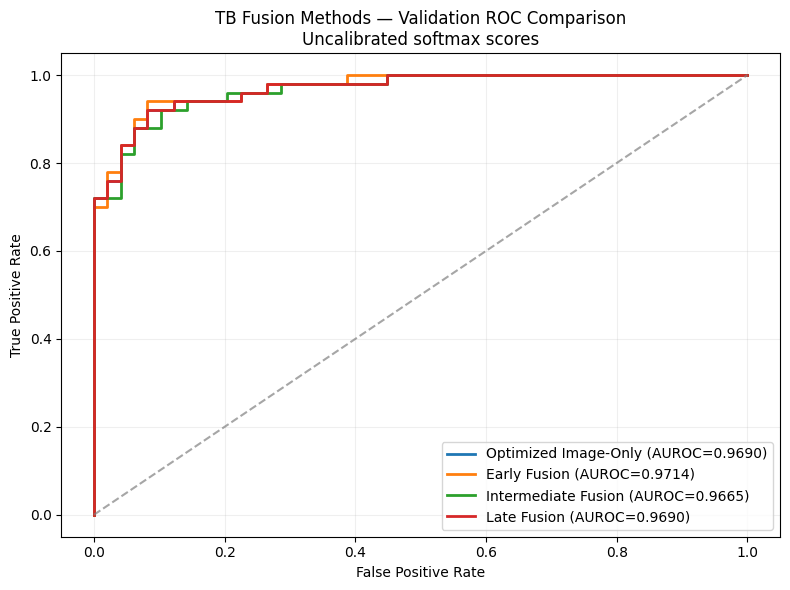


Saved comparison: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/fusion/tb_fusion_validation_comparison.csv
Saved aligned predictions: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/fusion/tb_fusion_validation_predictions.csv

Highest validation AUROC: Early Fusion


In [13]:

# ================================================================
# CELL 8 — FINAL TB FUSION VALIDATION COMPARISON
# Image-only vs Early vs Intermediate vs Late
# Best saved checkpoints | Validation only | PyTorch
# ================================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision.models import densenet121
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss,
    average_precision_score,
    roc_curve
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

fusion_dir = OUTPUT_DIR / "fusion"

image_path = (
    OUTPUT_DIR / "optimization" /
    "lr_3e-04" / "best_model.pth"
)
early_path = fusion_dir / "tb_early_fusion_best.pth"
intermediate_path = fusion_dir / "tb_intermediate_fusion_best.pth"
metadata_path = fusion_dir / "tb_late_metadata_best.pth"
late_config_path = fusion_dir / "tb_late_fusion_config.csv"

for path in [
    image_path,
    early_path,
    intermediate_path,
    metadata_path,
    late_config_path
]:
    assert path.exists(), f"Missing file: {path}"

# ------------------------------------------------
# 1. Load best checkpoints
# ------------------------------------------------

def make_image_model():
    model = densenet121(weights=None)
    model.classifier = nn.Linear(
        model.classifier.in_features, 2
    )
    return model


image_model = make_image_model()
image_model.load_state_dict(
    torch.load(
        image_path,
        map_location="cpu",
        weights_only=True
    ),
    strict=True
)
image_model = image_model.to(device).eval()


early_eval_model = make_image_model()

old_conv = early_eval_model.features.conv0
early_eval_model.features.conv0 = nn.Conv2d(
    5,
    old_conv.out_channels,
    kernel_size=old_conv.kernel_size,
    stride=old_conv.stride,
    padding=old_conv.padding,
    bias=False
)

early_eval_model.load_state_dict(
    torch.load(
        early_path,
        map_location="cpu",
        weights_only=True
    ),
    strict=True
)
early_eval_model = early_eval_model.to(device).eval()


# Uses TBIntermediateFusion class from Cell 6
intermediate_eval_model = TBIntermediateFusion(
    image_path
)
intermediate_eval_model.load_state_dict(
    torch.load(
        intermediate_path,
        map_location="cpu",
        weights_only=True
    ),
    strict=True
)
intermediate_eval_model = (
    intermediate_eval_model.to(device).eval()
)


# Uses TBLateMetadataModel class from Cell 7
metadata_eval_model = TBLateMetadataModel()
metadata_eval_model.load_state_dict(
    torch.load(
        metadata_path,
        map_location="cpu",
        weights_only=True
    ),
    strict=True
)
metadata_eval_model = (
    metadata_eval_model.to(device).eval()
)


late_config = pd.read_csv(late_config_path)
image_weight = float(
    late_config.loc[0, "image_weight"]
)
metadata_weight = float(
    late_config.loc[0, "metadata_weight"]
)

assert np.isclose(
    image_weight + metadata_weight, 1.0
)

# ------------------------------------------------
# 2. Run all models on identical validation batches
# ------------------------------------------------

# val_loader_mm from Cell 6:
# returns (RGB image, [age, sex], label)
# shuffle=False

assert len(val_dataset_mm) == 99

labels_all = []
image_scores_all = []
early_scores_all = []
intermediate_scores_all = []
metadata_scores_all = []

with torch.inference_mode():

    for images, metadata, labels in val_loader_mm:

        images = images.to(device)
        metadata = metadata.to(device)

        # Image-only
        image_logits = image_model(images)

        # Early fusion: RGB + two metadata channels
        h, w = images.shape[-2:]

        metadata_channels = (
            metadata[:, :, None, None]
            .expand(-1, -1, h, w)
        )

        early_inputs = torch.cat(
            [images, metadata_channels],
            dim=1
        )

        early_logits = early_eval_model(early_inputs)

        # Intermediate fusion
        intermediate_logits = (
            intermediate_eval_model(images, metadata)
        )

        # Metadata-only branch
        metadata_logits = metadata_eval_model(metadata)

        # All outputs are UNCALIBRATED softmax scores
        image_probs = torch.softmax(
            image_logits.float(), dim=1
        )[:, 1]

        early_probs = torch.softmax(
            early_logits.float(), dim=1
        )[:, 1]

        intermediate_probs = torch.softmax(
            intermediate_logits.float(), dim=1
        )[:, 1]

        metadata_probs = torch.softmax(
            metadata_logits.float(), dim=1
        )[:, 1]

        labels_all.extend(
            labels.numpy().tolist()
        )

        image_scores_all.extend(
            image_probs.cpu().numpy().tolist()
        )

        early_scores_all.extend(
            early_probs.cpu().numpy().tolist()
        )

        intermediate_scores_all.extend(
            intermediate_probs.cpu().numpy().tolist()
        )

        metadata_scores_all.extend(
            metadata_probs.cpu().numpy().tolist()
        )

y_true = np.asarray(labels_all, dtype=int)

image_scores = np.asarray(
    image_scores_all, dtype=float
)
early_scores = np.asarray(
    early_scores_all, dtype=float
)
intermediate_scores = np.asarray(
    intermediate_scores_all, dtype=float
)
metadata_scores = np.asarray(
    metadata_scores_all, dtype=float
)

late_scores = (
    image_weight * image_scores
    + metadata_weight * metadata_scores
)

# Verify predictions match validation CSV order
assert np.array_equal(
    y_true,
    val_fusion_df["label"].to_numpy()
)

assert len(y_true) == 99

# ------------------------------------------------
# 3. Calculate identical metrics for every model
# ------------------------------------------------

def calculate_metrics(name, scores, threshold=0.5):

    predictions = (
        scores >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "AUROC": roc_auc_score(
            y_true, scores
        ),
        "Accuracy": accuracy_score(
            y_true, predictions
        ),
        "Precision": precision_score(
            y_true, predictions,
            zero_division=0
        ),
        "Sensitivity": recall_score(
            y_true, predictions,
            zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "F1": f1_score(
            y_true, predictions,
            zero_division=0
        ),
        "Brier": brier_score_loss(
            y_true, scores
        ),
        "Average_Precision": average_precision_score(
            y_true, scores
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


model_scores = {
    "Optimized Image-Only": image_scores,
    "Early Fusion": early_scores,
    "Intermediate Fusion": intermediate_scores,
    "Late Fusion": late_scores
}

comparison_rows = [
    calculate_metrics(name, scores)
    for name, scores in model_scores.items()
]

comparison_df = pd.DataFrame(comparison_rows)

comparison_df = comparison_df.sort_values(
    "AUROC",
    ascending=False
).reset_index(drop=True)

print("\nFINAL TB FUSION VALIDATION COMPARISON")
print("=" * 100)
print("Validation images:", len(y_true))
print("Threshold: 0.50")
print("Scores: uncalibrated softmax outputs")
print(
    f"Late fusion weights: "
    f"image={image_weight:.2f}, "
    f"metadata={metadata_weight:.2f}"
)
print()

print(
    comparison_df[
        [
            "Model",
            "AUROC",
            "Accuracy",
            "Precision",
            "Sensitivity",
            "Specificity",
            "F1",
            "Brier",
            "FP",
            "FN"
        ]
    ].round(4).to_string(index=False)
)

# ------------------------------------------------
# 4. Plot ROC curves for all four models
# ------------------------------------------------

plt.figure(figsize=(8, 6))

for name, scores in model_scores.items():

    fpr, tpr, _ = roc_curve(
        y_true, scores
    )

    auc = roc_auc_score(
        y_true, scores
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUROC={auc:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    "--",
    color="gray",
    alpha=0.7
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    "TB Fusion Methods — Validation ROC Comparison\n"
    "Uncalibrated softmax scores"
)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 5. Save compact comparison and aligned predictions
# ------------------------------------------------

comparison_path = (
    fusion_dir /
    "tb_fusion_validation_comparison.csv"
)

predictions_path = (
    fusion_dir /
    "tb_fusion_validation_predictions.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

predictions_df = pd.DataFrame({
    "study_id": val_fusion_df["study_id"].to_numpy(),
    "true_label": y_true,
    "image_only_score": image_scores,
    "early_fusion_score": early_scores,
    "intermediate_fusion_score": intermediate_scores,
    "late_fusion_score": late_scores
})

predictions_df.to_csv(
    predictions_path,
    index=False
)

print("\nSaved comparison:", comparison_path)
print("Saved aligned predictions:", predictions_path)

print("\nHighest validation AUROC:",
      comparison_df.iloc[0]["Model"])


In [17]:

# ================================================================
# CELL 10 — FINAL TB EARLY-FUSION TEST EVALUATION
# Frozen checkpoint + validation-selected screening threshold
# PyTorch | One-time held-out test evaluation
# ================================================================

import sys
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import densenet121

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss,
    average_precision_score
)

# ------------------------------------------------
# 1. Fixed configuration
# ------------------------------------------------

SEED = 42
BATCH_SIZE = 16
TARGET_SENSITIVITY = 0.95

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BASE = Path(
    "/content/drive/MyDrive/Major_Project/Tuberculosis"
)

OUTPUT_DIR = BASE / "outputs"
FUSION_DIR = OUTPUT_DIR / "fusion"

MODEL_PATH = (
    FUSION_DIR / "tb_early_fusion_best.pth"
)

VAL_PREDICTIONS_PATH = (
    FUSION_DIR /
    "tb_fusion_validation_predictions.csv"
)

TRAIN_CSV = OUTPUT_DIR / "tb_train.csv"
TEST_CSV = OUTPUT_DIR / "tb_test.csv"

for path in [
    MODEL_PATH,
    VAL_PREDICTIONS_PATH,
    TRAIN_CSV,
    TEST_CSV
]:
    assert path.exists(), f"Missing: {path}"

# ------------------------------------------------
# 2. Recover exact screening threshold
#    FROM VALIDATION ONLY
# ------------------------------------------------

val_predictions = pd.read_csv(
    VAL_PREDICTIONS_PATH
)

val_labels = val_predictions[
    "true_label"
].to_numpy(dtype=int)

val_scores = val_predictions[
    "early_fusion_score"
].to_numpy(dtype=float)

assert len(val_labels) == 99
assert (val_labels == 1).sum() == 50

candidate_thresholds = np.unique(
    np.concatenate([
        val_scores,
        np.array([0.0])
    ])
)

valid_candidates = []

for threshold in candidate_thresholds:

    predictions = (
        val_scores >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        val_labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    if sensitivity >= TARGET_SENSITIVITY - 1e-12:
        valid_candidates.append(
            (
                specificity,
                float(threshold)
            )
        )

assert valid_candidates

# Same rule used in Cell 9:
# maximize specificity; break ties by higher threshold
_, SCREENING_THRESHOLD = max(valid_candidates)

print("FROZEN MODEL CONFIGURATION")
print("=" * 65)
print("Model: Early-Fusion DenseNet-121")
print("Checkpoint:", MODEL_PATH)
print(
    f"Screening threshold: "
    f"{SCREENING_THRESHOLD:.12f}"
)
print("Threshold source: validation set only")

# ------------------------------------------------
# 3. Recover training-only metadata statistics
# ------------------------------------------------

train_df_final = pd.read_csv(TRAIN_CSV)
test_df_final = pd.read_csv(TEST_CSV)

AGE_MEAN = float(train_df_final["age"].mean())
AGE_STD = float(
    train_df_final["age"].std(ddof=0)
)

assert AGE_STD > 0

assert set(
    test_df_final["sex"].unique()
).issubset({"Male", "Female"})

assert test_df_final["age"].notna().all()
assert test_df_final["sex"].notna().all()

assert len(test_df_final) == 100

# Verify held-out study IDs do not overlap training
assert set(
    train_df_final["study_id"]
).isdisjoint(
    set(test_df_final["study_id"])
)

# Encode metadata exactly as in training
test_df_final["age_normalized"] = (
    test_df_final["age"] - AGE_MEAN
) / AGE_STD

test_df_final["sex_encoded"] = (
    test_df_final["sex"]
    .map({"Female": 0, "Male": 1})
    .astype(float)
)

# ------------------------------------------------
# 4. Reproduce image preprocessing
# ------------------------------------------------

sys.path.insert(0, str(OUTPUT_DIR))
from tb_preprocessing import preprocess_tb_image

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class TBFinalEarlyFusionDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image = preprocess_tb_image(
            row["image_path"]
        )

        image = test_transform(image)

        metadata = torch.tensor(
            [
                float(row["age_normalized"]),
                float(row["sex_encoded"])
            ],
            dtype=torch.float32
        )

        metadata_channels = (
            metadata[:, None, None]
            .expand(
                2,
                image.shape[1],
                image.shape[2]
            )
        )

        fused_input = torch.cat(
            [image, metadata_channels],
            dim=0
        )

        label = int(row["label"])

        return fused_input, label


test_dataset = TBFinalEarlyFusionDataset(
    test_df_final
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# ------------------------------------------------
# 5. Reconstruct early-fusion architecture
# ------------------------------------------------

model = densenet121(weights=None)

model.classifier = nn.Linear(
    model.classifier.in_features,
    2
)

old_conv = model.features.conv0

model.features.conv0 = nn.Conv2d(
    in_channels=5,
    out_channels=old_conv.out_channels,
    kernel_size=old_conv.kernel_size,
    stride=old_conv.stride,
    padding=old_conv.padding,
    bias=False
)

model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location="cpu",
        weights_only=True
    ),
    strict=True
)

model = model.to(device).eval()

# ------------------------------------------------
# 6. ONE-TIME HELD-OUT TEST INFERENCE
# ------------------------------------------------

test_labels = []
test_scores = []

with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(device)

        logits = model(images)

        # Uncalibrated softmax TB score
        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        test_labels.extend(
            labels.numpy().tolist()
        )

        test_scores.extend(
            probabilities.cpu().numpy().tolist()
        )

y_true = np.asarray(
    test_labels,
    dtype=int
)

y_score = np.asarray(
    test_scores,
    dtype=float
)

assert len(y_true) == 100
assert np.array_equal(
    y_true,
    test_df_final["label"].to_numpy()
)

# ------------------------------------------------
# 7. Calculate test metrics at both thresholds
# ------------------------------------------------

def evaluate_threshold(
    y_true,
    scores,
    threshold,
    threshold_name
):

    y_pred = (
        scores >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "model": "Early-Fusion DenseNet-121",
        "threshold_type": threshold_name,
        "threshold": float(threshold),
        "AUROC": roc_auc_score(
            y_true, scores
        ),
        "Accuracy": accuracy_score(
            y_true, y_pred
        ),
        "Precision": precision_score(
            y_true, y_pred,
            zero_division=0
        ),
        "Sensitivity": recall_score(
            y_true, y_pred,
            zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "F1": f1_score(
            y_true, y_pred,
            zero_division=0
        ),
        "Brier": brier_score_loss(
            y_true, scores
        ),
        "Average_Precision": average_precision_score(
            y_true, scores
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


default_metrics = evaluate_threshold(
    y_true,
    y_score,
    threshold=0.5,
    threshold_name="default_0.5"
)

screening_metrics = evaluate_threshold(
    y_true,
    y_score,
    threshold=SCREENING_THRESHOLD,
    threshold_name="validation_selected_screening"
)

results_df = pd.DataFrame([
    default_metrics,
    screening_metrics
])

print("\nFINAL HELD-OUT TB TEST RESULTS")
print("=" * 100)
print("Test images:", len(y_true))
print("TB-positive:", int((y_true == 1).sum()))
print("Normal:", int((y_true == 0).sum()))
print("Scores: UNCALIBRATED softmax outputs")
print()

print(
    results_df[
        [
            "threshold_type",
            "threshold",
            "AUROC",
            "Accuracy",
            "Precision",
            "Sensitivity",
            "Specificity",
            "F1",
            "Brier",
            "TN",
            "FP",
            "FN",
            "TP"
        ]
    ].round(6).to_string(index=False)
)

# ------------------------------------------------
# 8. Save final test results and predictions
# ------------------------------------------------

metrics_path = (
    FUSION_DIR /
    "tb_early_fusion_final_test_metrics.csv"
)

predictions_path = (
    FUSION_DIR /
    "tb_early_fusion_final_test_predictions.csv"
)

config_path = (
    FUSION_DIR /
    "tb_early_fusion_deployment_config.json"
)

results_df.to_csv(
    metrics_path,
    index=False
)

predictions_df = pd.DataFrame({
    "study_id": test_df_final["study_id"],
    "true_label": y_true,
    "tb_softmax_score_uncalibrated": y_score,
    "prediction_at_0_5": (
        y_score >= 0.5
    ).astype(int),
    "prediction_at_screening_threshold": (
        y_score >= SCREENING_THRESHOLD
    ).astype(int)
})

predictions_df.to_csv(
    predictions_path,
    index=False
)

deployment_config = {
    "model": "early_fusion_densenet121",
    "checkpoint": str(MODEL_PATH),
    "selection_metric": "validation_auroc",
    "validation_auroc": 0.971429,
    "input_channels": 5,
    "input_size": [224, 224],
    "metadata_features": [
        "age_normalized",
        "sex_encoded"
    ],
    "age_mean": AGE_MEAN,
    "age_std": AGE_STD,
    "sex_encoding": {
        "Female": 0,
        "Male": 1
    },
    "image_normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225]
    },
    "default_threshold": 0.5,
    "screening_threshold": SCREENING_THRESHOLD,
    "screening_threshold_source": "validation",
    "score_type": "uncalibrated_softmax",
    "intended_use": "research_prototype_only"
}

with open(config_path, "w") as file:
    json.dump(
        deployment_config,
        file,
        indent=2
    )

print("\nSAVED FINAL ARTIFACTS")
print("=" * 65)
print("Test metrics:", metrics_path)
print("Test predictions:", predictions_path)
print("Deployment config:", config_path)
print("Model checkpoint:", MODEL_PATH)


FROZEN MODEL CONFIGURATION
Model: Early-Fusion DenseNet-121
Checkpoint: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/fusion/tb_early_fusion_best.pth
Screening threshold: 0.008798536845
Threshold source: validation set only

FINAL HELD-OUT TB TEST RESULTS
Test images: 100
TB-positive: 51
Normal: 49
Scores: UNCALIBRATED softmax outputs

               threshold_type  threshold   AUROC  Accuracy  Precision  Sensitivity  Specificity      F1    Brier  TN  FP  FN  TP
                  default_0.5   0.500000 0.97559      0.89   0.976190     0.803922     0.979592 0.88172 0.082595  48   1  10  41
validation_selected_screening   0.008799 0.97559      0.90   0.872727     0.941176     0.857143 0.90566 0.082595  42   7   3  48

SAVED FINAL ARTIFACTS
Test metrics: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/fusion/tb_early_fusion_final_test_metrics.csv
Test predictions: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/fusion/tb_early_fusion_final_test_predictions.

In [18]:

# ============================================================
# CELL 11 — CREATE REUSABLE TB EARLY-FUSION INFERENCE MODULE
# ============================================================

from pathlib import Path

FUSION_DIR = Path(
    "/content/drive/MyDrive/Major_Project/"
    "Tuberculosis/outputs/fusion"
)

FUSION_DIR.mkdir(parents=True, exist_ok=True)

module_path = FUSION_DIR / "tb_early_fusion_inference.py"

module_code = r'''
import json
import sys
from pathlib import Path

import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms
from torchvision.models import densenet121


class TBEarlyFusionPredictor:
    """
    Research-only TB screening predictor.

    Inputs:
        Chest X-ray image, age, sex

    Output:
        Uncalibrated softmax score and screening flag.

    This model is not clinically validated and must not
    be used as an autonomous diagnostic system.
    """

    def __init__(
        self,
        config_path,
        device=None
    ):
        self.config_path = Path(config_path).resolve()

        if not self.config_path.is_file():
            raise FileNotFoundError(
                f"Missing configuration: {self.config_path}"
            )

        with open(self.config_path, "r") as f:
            self.config = json.load(f)

        self.device = torch.device(
            device or (
                "cuda" if torch.cuda.is_available()
                else "cpu"
            )
        )

        checkpoint_path = Path(
            self.config["checkpoint"]
        )

        if not checkpoint_path.is_file():
            raise FileNotFoundError(
                f"Missing checkpoint: {checkpoint_path}"
            )

        self.threshold = float(
            self.config["screening_threshold"]
        )

        self.age_mean = float(
            self.config["age_mean"]
        )

        self.age_std = float(
            self.config["age_std"]
        )

        if self.age_std <= 0:
            raise ValueError(
                "Invalid age normalization statistics."
            )

        self.sex_encoding = self.config[
            "sex_encoding"
        ]

        # Preprocessing module created during TB preparation.
        outputs_dir = self.config_path.parent.parent

        if str(outputs_dir) not in sys.path:
            sys.path.insert(0, str(outputs_dir))

        from tb_preprocessing import preprocess_tb_image

        self.preprocess_tb_image = preprocess_tb_image

        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(
                mean=self.config[
                    "image_normalization"
                ]["mean"],
                std=self.config[
                    "image_normalization"
                ]["std"]
            )
        ])

        # Reconstruct the exact 5-channel architecture.
        model = densenet121(weights=None)

        model.classifier = nn.Linear(
            model.classifier.in_features,
            2
        )

        original_conv = model.features.conv0

        model.features.conv0 = nn.Conv2d(
            in_channels=5,
            out_channels=original_conv.out_channels,
            kernel_size=original_conv.kernel_size,
            stride=original_conv.stride,
            padding=original_conv.padding,
            bias=False
        )

        state_dict = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        model.load_state_dict(
            state_dict,
            strict=True
        )

        self.model = model.to(
            self.device
        ).eval()

    def predict(
        self,
        image_path,
        age,
        sex
    ):
        image_path = Path(image_path)

        if not image_path.is_file():
            raise FileNotFoundError(
                f"Image not found: {image_path}"
            )

        try:
            age = float(age)
        except (TypeError, ValueError):
            raise ValueError(
                "Age must be numeric."
            )

        import math

        if not math.isfinite(age) or not (0 <= age <= 120):
            raise ValueError(
                "Age must be between 0 and 120."
            )

        if sex not in self.sex_encoding:
            raise ValueError(
                "Sex must be 'Male' or 'Female'."
            )

        image = self.preprocess_tb_image(
            str(image_path)
        )

        image_tensor = self.transform(
            image
        )

        age_normalized = (
            age - self.age_mean
        ) / self.age_std

        sex_encoded = float(
            self.sex_encoding[sex]
        )

        metadata = torch.tensor(
            [age_normalized, sex_encoded],
            dtype=torch.float32
        )

        metadata_channels = (
            metadata[:, None, None]
            .expand(
                2,
                image_tensor.shape[1],
                image_tensor.shape[2]
            )
        )

        fused_tensor = torch.cat(
            [image_tensor, metadata_channels],
            dim=0
        ).unsqueeze(0)

        fused_tensor = fused_tensor.to(
            self.device
        )

        with torch.inference_mode():
            logits = self.model(
                fused_tensor
            )

            tb_score = torch.softmax(
                logits.float(),
                dim=1
            )[0, 1].item()

        screening_flag = (
            tb_score >= self.threshold
        )

        return {
            "model": "TB Early-Fusion DenseNet-121",
            "tb_score_uncalibrated": float(tb_score),
            "screening_threshold": self.threshold,
            "screening_flag": bool(screening_flag),
            "screening_result": (
                "TB screening flag"
                if screening_flag
                else "No TB screening flag"
            ),
            "disclaimer": (
                "Research prototype only. "
                "Not a clinical diagnosis."
            )
        }
'''

module_path.write_text(
    module_code,
    encoding="utf-8"
)

print("INFERENCE MODULE CREATED")
print("=" * 65)
print("Path:", module_path)
print("Size:", module_path.stat().st_size, "bytes")


INFERENCE MODULE CREATED
Path: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/fusion/tb_early_fusion_inference.py
Size: 5647 bytes


In [19]:

# ================================================================
# CELL 12 — VERIFY TB EARLY-FUSION DEPLOYMENT CONSISTENCY
# ================================================================

import sys
import importlib
import numpy as np
import pandas as pd

from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Major_Project/Tuberculosis"
)

FUSION_DIR = BASE / "outputs" / "fusion"

CONFIG_PATH = (
    FUSION_DIR /
    "tb_early_fusion_deployment_config.json"
)

TEST_CSV = BASE / "outputs" / "tb_test.csv"

SAVED_PREDICTIONS_PATH = (
    FUSION_DIR /
    "tb_early_fusion_final_test_predictions.csv"
)

# ------------------------------------------------
# 1. Import the deployment module
# ------------------------------------------------

sys.path.insert(0, str(FUSION_DIR))

import tb_early_fusion_inference

# Reload if this notebook previously imported the module
importlib.reload(tb_early_fusion_inference)

TBEarlyFusionPredictor = (
    tb_early_fusion_inference.TBEarlyFusionPredictor
)

# ------------------------------------------------
# 2. Load the frozen predictor
# ------------------------------------------------

predictor = TBEarlyFusionPredictor(
    config_path=CONFIG_PATH
)

print("DEPLOYMENT MODEL LOADED")
print("=" * 65)
print("Device:", predictor.device)
print(
    "Screening threshold:",
    f"{predictor.threshold:.12f}"
)

# ------------------------------------------------
# 3. Load the saved test predictions
# ------------------------------------------------

test_df = pd.read_csv(TEST_CSV)

saved_df = pd.read_csv(
    SAVED_PREDICTIONS_PATH
)

assert len(test_df) == 100
assert len(saved_df) == 100

# Match by study ID rather than assuming row order
comparison_df = test_df[
    [
        "study_id",
        "image_path",
        "age",
        "sex",
        "label"
    ]
].merge(
    saved_df[
        [
            "study_id",
            "true_label",
            "tb_softmax_score_uncalibrated",
            "prediction_at_screening_threshold"
        ]
    ],
    on="study_id",
    how="inner",
    validate="one_to_one"
)

assert len(comparison_df) == 100

assert np.array_equal(
    comparison_df["label"].to_numpy(),
    comparison_df["true_label"].to_numpy()
)

# ------------------------------------------------
# 4. Run deployment inference on all test images
# ------------------------------------------------

deployment_scores = []
deployment_flags = []

for index, row in comparison_df.iterrows():

    result = predictor.predict(
        image_path=row["image_path"],
        age=row["age"],
        sex=row["sex"]
    )

    deployment_scores.append(
        result["tb_score_uncalibrated"]
    )

    deployment_flags.append(
        int(result["screening_flag"])
    )

    if (index + 1) % 20 == 0:
        print(
            f"Verified {index + 1}/100 images"
        )

comparison_df["deployment_score"] = (
    deployment_scores
)

comparison_df["deployment_flag"] = (
    deployment_flags
)

# ------------------------------------------------
# 5. Check numerical consistency
# ------------------------------------------------

saved_scores = comparison_df[
    "tb_softmax_score_uncalibrated"
].to_numpy(dtype=float)

new_scores = comparison_df[
    "deployment_score"
].to_numpy(dtype=float)

max_absolute_difference = float(
    np.max(
        np.abs(saved_scores - new_scores)
    )
)

saved_flags = comparison_df[
    "prediction_at_screening_threshold"
].to_numpy(dtype=int)

new_flags = comparison_df[
    "deployment_flag"
].to_numpy(dtype=int)

matching_flags = int(
    np.sum(saved_flags == new_flags)
)

score_match = np.allclose(
    saved_scores,
    new_scores,
    rtol=1e-5,
    atol=1e-6
)

flags_match = np.array_equal(
    saved_flags,
    new_flags
)

# ------------------------------------------------
# 6. Display consistency results
# ------------------------------------------------

print("\nDEPLOYMENT CONSISTENCY RESULTS")
print("=" * 65)

print(
    "Maximum absolute score difference:",
    f"{max_absolute_difference:.10f}"
)

print(
    "Screening classifications matched:",
    f"{matching_flags}/100"
)

print(
    "Score consistency:",
    "PASS" if score_match else "FAIL"
)

print(
    "Classification consistency:",
    "PASS" if flags_match else "FAIL"
)

if score_match and flags_match:
    print(
        "\nSUCCESS: Deployment inference reproduces "
        "the frozen test evaluation."
    )
else:
    print(
        "\nWARNING: Deployment consistency check failed."
    )
    print(
        "Investigate preprocessing, model loading, "
        "and metadata encoding before integration."
    )

# ------------------------------------------------
# 7. Show a few example predictions
# ------------------------------------------------

print("\nSAMPLE PREDICTIONS")
print("=" * 65)

print(
    comparison_df[
        [
            "study_id",
            "true_label",
            "tb_softmax_score_uncalibrated",
            "deployment_score",
            "deployment_flag"
        ]
    ].head(5).to_string(index=False)
)


DEPLOYMENT MODEL LOADED
Device: cuda
Screening threshold: 0.008798536845
Verified 20/100 images
Verified 40/100 images
Verified 60/100 images
Verified 80/100 images
Verified 100/100 images

DEPLOYMENT CONSISTENCY RESULTS
Maximum absolute score difference: 0.0052995086
Screening classifications matched: 100/100
Score consistency: FAIL
Classification consistency: PASS

Investigate preprocessing, model loading, and metadata encoding before integration.

SAMPLE PREDICTIONS
         study_id  true_label  tb_softmax_score_uncalibrated  deployment_score  deployment_flag
CHNCXR_0609_1.png           1                       0.973544          0.973163                1
CHNCXR_0167_0.png           0                       0.339179          0.341409                1
CHNCXR_0284_0.png           0                       0.000019          0.000020                0
CHNCXR_0236_0.png           0                       0.000306          0.000311                0
CHNCXR_0063_0.png           0                 

In [20]:

# ================================================================
# CELL 13 — DIAGNOSE DEPLOYMENT SCORE MISMATCH
# Compare original batched inference vs deployment model
# ================================================================

import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader

# Uses objects already created in Cells 10 and 12:
# predictor, test_dataset, test_df_final,
# comparison_df, and saved test predictions.

assert predictor.model.training is False

# ------------------------------------------------
# 1. Re-run inference in the ORIGINAL batch format
#    using the DEPLOYMENT model
# ------------------------------------------------

diagnostic_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=(predictor.device.type == "cuda")
)

batched_scores = []

with torch.inference_mode():

    for images, labels in diagnostic_loader:

        images = images.to(predictor.device)

        logits = predictor.model(images)

        scores = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        batched_scores.extend(
            scores.cpu().numpy().tolist()
        )

batched_scores = np.asarray(
    batched_scores,
    dtype=float
)

# ------------------------------------------------
# 2. Align results by study ID
# ------------------------------------------------

batched_df = pd.DataFrame({
    "study_id": test_df_final["study_id"].values,
    "batched_score": batched_scores
})

diagnostic_df = comparison_df.merge(
    batched_df,
    on="study_id",
    how="inner",
    validate="one_to_one"
)

assert len(diagnostic_df) == 100

original_scores = diagnostic_df[
    "tb_softmax_score_uncalibrated"
].to_numpy(dtype=float)

single_scores = diagnostic_df[
    "deployment_score"
].to_numpy(dtype=float)

batch_scores = diagnostic_df[
    "batched_score"
].to_numpy(dtype=float)

# ------------------------------------------------
# 3. Measure the differences
# ------------------------------------------------

single_diff = np.abs(
    original_scores - single_scores
)

batch_diff = np.abs(
    original_scores - batch_scores
)

single_vs_batch_diff = np.abs(
    single_scores - batch_scores
)

print("TB DEPLOYMENT DIAGNOSTIC")
print("=" * 70)

print(
    "Original vs single-image max difference:",
    f"{single_diff.max():.10f}"
)

print(
    "Original vs batch-16 max difference:",
    f"{batch_diff.max():.10f}"
)

print(
    "Single-image vs batch-16 max difference:",
    f"{single_vs_batch_diff.max():.10f}"
)

print()

print(
    "Original vs batch-16 scores match:",
    np.allclose(
        original_scores,
        batch_scores,
        rtol=1e-5,
        atol=1e-6
    )
)

print(
    "Original vs batch-16 flags match:",
    np.array_equal(
        original_scores >= predictor.threshold,
        batch_scores >= predictor.threshold
    )
)

# ------------------------------------------------
# 4. Display largest mismatches
# ------------------------------------------------

diagnostic_df["single_abs_diff"] = single_diff
diagnostic_df["batch_abs_diff"] = batch_diff

print("\nLARGEST ORIGINAL vs SINGLE-IMAGE DIFFERENCES")
print("=" * 70)

print(
    diagnostic_df[
        [
            "study_id",
            "tb_softmax_score_uncalibrated",
            "deployment_score",
            "batched_score",
            "single_abs_diff",
            "batch_abs_diff"
        ]
    ]
    .sort_values(
        "single_abs_diff",
        ascending=False
    )
    .head(10)
    .to_string(index=False)
)


TB DEPLOYMENT DIAGNOSTIC
Original vs single-image max difference: 0.0052995086
Original vs batch-16 max difference: 0.0000000000
Single-image vs batch-16 max difference: 0.0052995086

Original vs batch-16 scores match: True
Original vs batch-16 flags match: True

LARGEST ORIGINAL vs SINGLE-IMAGE DIFFERENCES
         study_id  tb_softmax_score_uncalibrated  deployment_score  batched_score  single_abs_diff  batch_abs_diff
CHNCXR_0599_1.png                       0.283296          0.277997       0.283296         0.005300    0.000000e+00
CHNCXR_0088_0.png                       0.271103          0.275607       0.271103         0.004504    0.000000e+00
CHNCXR_0626_1.png                       0.518550          0.521840       0.518550         0.003290    0.000000e+00
CHNCXR_0167_0.png                       0.339179          0.341409       0.339179         0.002230    0.000000e+00
CHNCXR_0021_0.png                       0.056370          0.054429       0.056370         0.001941    9.020562e-17
C

In [21]:

# ================================================================
# CELL 14 — CPU SINGLE-IMAGE DEPLOYMENT VERIFICATION
# No retraining, no model or threshold changes
# ================================================================

import numpy as np
import pandas as pd

from tb_early_fusion_inference import TBEarlyFusionPredictor

# 1. Load the SAME frozen model on CPU
cpu_predictor = TBEarlyFusionPredictor(
    config_path=CONFIG_PATH,
    device="cpu"
)

# 2. Run all 100 samples individually
cpu_scores = []
cpu_flags = []

for i, row in comparison_df.iterrows():

    result = cpu_predictor.predict(
        image_path=row["image_path"],
        age=row["age"],
        sex=row["sex"]
    )

    cpu_scores.append(
        result["tb_score_uncalibrated"]
    )

    cpu_flags.append(
        int(result["screening_flag"])
    )

    if (i + 1) % 20 == 0:
        print(f"CPU verified {i + 1}/100")

cpu_scores = np.asarray(cpu_scores, dtype=float)
cpu_flags = np.asarray(cpu_flags, dtype=int)

# 3. Compare CPU with frozen test scores
saved_scores = comparison_df[
    "tb_softmax_score_uncalibrated"
].to_numpy(dtype=float)

saved_flags = comparison_df[
    "prediction_at_screening_threshold"
].to_numpy(dtype=int)

gpu_single_scores = comparison_df[
    "deployment_score"
].to_numpy(dtype=float)

print("\nCPU DEPLOYMENT VERIFICATION")
print("=" * 65)

print(
    "CPU vs frozen batch-16 max difference:",
    f"{np.max(np.abs(cpu_scores - saved_scores)):.10f}"
)

print(
    "CPU vs GPU single-image max difference:",
    f"{np.max(np.abs(cpu_scores - gpu_single_scores)):.10f}"
)

print(
    "CPU screening classifications matched:",
    f"{np.sum(cpu_flags == saved_flags)}/100"
)

print(
    "CPU screening flag consistency:",
    "PASS" if np.array_equal(
        cpu_flags, saved_flags
    ) else "FAIL"
)

# 4. Check repeatability on one sample
sample = comparison_df.iloc[0]

repeat_scores = [
    cpu_predictor.predict(
        image_path=sample["image_path"],
        age=sample["age"],
        sex=sample["sex"]
    )["tb_score_uncalibrated"]
    for _ in range(3)
]

print("\nCPU REPEATABILITY")
print("=" * 65)
print("Repeated scores:", repeat_scores)
print(
    "Repeatable:",
    np.allclose(
        repeat_scores,
        repeat_scores[0],
        rtol=0,
        atol=1e-7
    )
)


CPU verified 20/100
CPU verified 40/100
CPU verified 60/100
CPU verified 80/100
CPU verified 100/100

CPU DEPLOYMENT VERIFICATION
CPU vs frozen batch-16 max difference: 0.0018884540
CPU vs GPU single-image max difference: 0.0047037601
CPU screening classifications matched: 100/100
CPU screening flag consistency: PASS

CPU REPEATABILITY
Repeated scores: [0.9735804796218872, 0.9735804796218872, 0.9735804796218872]
Repeatable: True
